<p>

<h1><b><center></center></b></h1>
<h1><b><center>Minería de Datos</center></b></h1>
<h2><b><center>Tercer proyecto computacional</center></b><h2>
<h3><b><center>Edad cinemática de poblaciones estelares de la Vía Láctea</center></b><h3>

</p>

<hr/>
<b>Nombre</b>: Gabriel Rodríguez Suárez
<br/>
<b>Cédula</b>: 1089931997
<hr/>
<b>Estado</b>: En proceso.
<br/>
<b>Última actualización</b>: 15-11-2026
<br/>
<b>Tiempo de ejecucción</b>: 3 minutos aprox.

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
# Módulos de librerías
import astropy.units as u
import matplotlib.pyplot as plt
# Rutinas específicas
from astropy.coordinates import SkyCoord, CartesianRepresentation
from astropy.table import Table
from astroquery.gaia import Gaia
#from astroquery.simbad import Simbad
from sklearn.preprocessing import StandardScaler
from sklearn.mixture import GaussianMixture

The current archive release 3.15 contains two breaking changes. Please see https://www.cosmos.esa.int/web/gaia/news#GACSrelease315 for details. In case of questions or feedback, please consult the Gaia helpdesk at https://www.cosmos.esa.int/web/gaia/gaia-helpdesk.


## **Lower Centaurus-Crux association**

El cúmulo abierto de Lower Centaurus-Crux está ubicado en las coordenadas ecuatoriales de ICRS:

$$\text{RA}:[12h,19min,00s]$$
$$\text{DEC}:[-57,06',00'']$$

Es una de las regiones de formación estelar de estrellas tipo O más cercanas al Sistema Solar, ubicado en las constelaciones de Lupus, Centauro y Crux.

Para el momento de desarrollar el proyecto SIMBAD estaba caído en sus servidores de `astroquery`, por lo que ingresamos a la base de datos y cargaremos entonces la VOTABLE que contiene los datos solicitados.

In [2]:
simbad_LCC = Table.read('simbad_LCC_votable.vot', format='votable')
#simbad2_LCC = Table.read('simbad (2)', format='votable')

Crearemos una nueva tabla sólo con los datos que realmene necesitamos para nuestro trabajo.

In [3]:
sub_LCC = simbad_LCC['RA_d', 'DEC_d', 'PLX_plx']

Para hacer el cross-match con los datos de Gaia, queremos identificar cuál es la estrella más cercana y la más lejana, para ello pasaremos por tres filtros los datos:

1. Que el paralaje no sea nulo ni negativo.
2. Que los movimientos propios no sean nulos o negativos.
3. Que el paralaje esté acotado entre una distancia de la estrella maś cercana a la Tierra y la más lejana registrada.

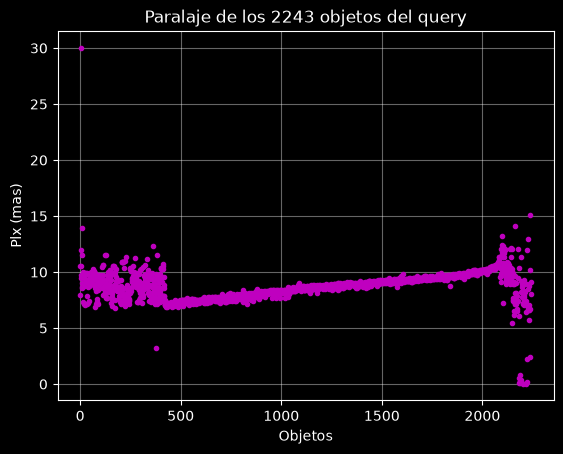

In [4]:
plt.style.use("dark_background")

plt.plot(sub_LCC['PLX_plx'], 'm.')
plt.title(f"Paralaje de los {len(sub_LCC)} objetos del query")
plt.xlabel('Objetos')
plt.ylabel('Plx (mas)')
plt.grid(alpha=0.4)
plt.show()

Hacemos este primer query para poder filtrar los datos de Gaia con mayor facilidad. Primero debe tenerse en cuenta que el paralaje está limitado por la resolución de los telescopios, aquí en el gráfico anterior podemos ver que hay objetos con paralajes casi cero, lo que indica que son muy distantes. Por el contrario, aquellos con paralajes muy grandes son objetos más cercanos a La Tiera.

Lo que sí puede observarse es una tendencia bien definida de los datos de paralaje de SIMBAD de LCC association a estar en un rango entre 5 mas y 15 mas, por lo que nuestro query de Gaia será delimitado por estos valores de paralaje.

In [5]:
def sex2dec(d, arcmin, arcsec):
  if d < 0:
    decs = d - arcmin / 60 - arcsec / 3600
  else:
    decs = d + arcmin / 60 + arcsec / 3600
  return decs

In [6]:
ra_LCC = sex2dec(12,19,0) * 15
print(f"RA: {ra_LCC}°")

dec_LCC = sex2dec(-57,6,0)
print(f"dec: {dec_LCC}°")

RA: 184.75°
dec: -57.1°


In [7]:
# Aquí hacemos el query al centro de LCC:
coords_LCC = SkyCoord(
    ra= ra_LCC,
    dec = dec_LCC,
    unit=(u.degree, u.degree),
    frame="icrs"
)

print("SkyCoord de LCC association:")
print(coords_LCC)

SkyCoord de LCC association:
<SkyCoord (ICRS): (ra, dec) in deg
    (184.75, -57.1)>


Este fue el query hecho a Gaia para LCC, queda comentado ya que se descargaron los datos respectivos para no molestar al sistema cada vez que se corría el código.

In [8]:
# query_LCC = f"""
# SELECT TOP 6000
# source_id,
# ra,
# dec,
# parallax,
# parallax_over_error AS plx_oerr,
# pmra,
# pmra_error,
# pmdec,
# pmdec_error,
# phot_g_mean_mag,
# radial_velocity,
# radial_velocity_error AS rv_error
# FROM gaiadr3.gaia_source
# WHERE CONTAINS(POINT('ICRS', ra, dec), CIRCLE('ICRS', {ra_LCC}, {dec_LCC}, 5.0)) = 1
# AND parallax >= 5 AND parallax <= 15
# AND pmra IS NOT NULL
# AND pmdec IS NOT NULL
# AND phot_g_mean_mag < 14.0
# AND radial_velocity IS NOT NULL
# """

# job_LCC = Gaia.launch_job(query_LCC)
# result_LCC = job_LCC.get_results()

In [9]:
result_LCC = Table.read('lcc_cartesian_data.fits', format='fits')
len(result_LCC)

1066

## **Filtrado por errores**

Para que nuestro futuro modelo de Gaussian Mixtures no sufra explicando datos crudos con posibles errores instrumentales vamos a hacer dos filtros principales:

1. Error absoluto de movimiento propio: definiremos una tolerancia máxima para el error absoluto de ambas componentes.

2. Error relativo de paralaje: en los papers e investigaciones de éste se acostumbra a tener una $S/N > 10$, con tal de que no tengamos datos

In [10]:
mask_LCC_plx = result_LCC['plx_oerr'] > 10

filtro_1_LCC = result_LCC[mask_LCC_plx]
print(len(result_LCC), len(filtro_1_LCC))

1066 1060


### **2) Incertidumbres de movimientos propios**

Ahora vamos a revisar con lupa los movimientos propios.

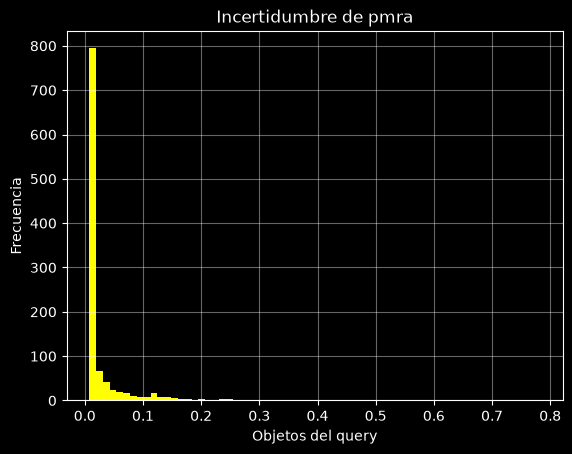

In [11]:
plt.hist(result_LCC['pmra_error'], bins='auto', color='yellow')
plt.title("Incertidumbre de pmra")
plt.xlabel('Objetos del query')
plt.ylabel('Frecuencia')
plt.grid(alpha=0.4)
plt.show()

In [12]:
mask_pm_LCC = (filtro_1_LCC['pmra_error'] < 0.05) & (filtro_1_LCC['pmdec_error'] < 0.05)

filtro_2_LCC = filtro_1_LCC[mask_pm_LCC]
len(filtro_2_LCC)

912

### **Filtro por velocidad radial**

In [13]:
errores_rv_rel = np.abs(filtro_2_LCC['rv_error'].data / filtro_2_LCC['radial_velocity'].data)

mask3_LCC = errores_rv_rel <= 0.2

filtro_3_LCC = filtro_2_LCC[mask3_LCC]

len(filtro_3_LCC)

695

## **Método de Gaussian Mixtures:**

Ahora, vamos a trabajar con los datos que tenemos y vamos a aplicar el método de Gaussian Mixtures para cuatro componentes: los movimientos propios, el paralaje y la velocidad radial. Aquí es necesario escalar los datos a curvas normales estándar ya que tenemos tres unidades diferentes, entonces no debemos meter todo a la licuadora y hacer un salpicón.

In [14]:
Xs_LCC = np.column_stack(
    [filtro_3_LCC['pmra'], filtro_3_LCC['pmdec'], 
     filtro_3_LCC['parallax'], filtro_3_LCC['radial_velocity']]
)

scaler = StandardScaler()
Xns_LCC = scaler.fit_transform(Xs_LCC)

Vamos a implementar un código que está en el repositorio del curso de Minería de Datos del pregrado de Astronomía de la Universidad de ANtioquia (autoría de los doctores Germán Chaparro y Esteban Silva), simplemente para calcular el número necesario de clusters para nuestro mdelo utilizando el criterio de información Bayesiana (BIC). 

Éste criterio penaliza los modelos complejos y elige modelos simples (pero tampoco tanto), por lo que veremos la cantidad de clusters que va a generar dado nuestro espacio 4-D de parámetros con el que describimos el cúmulo.

Best number of clusters according to BIC: 5


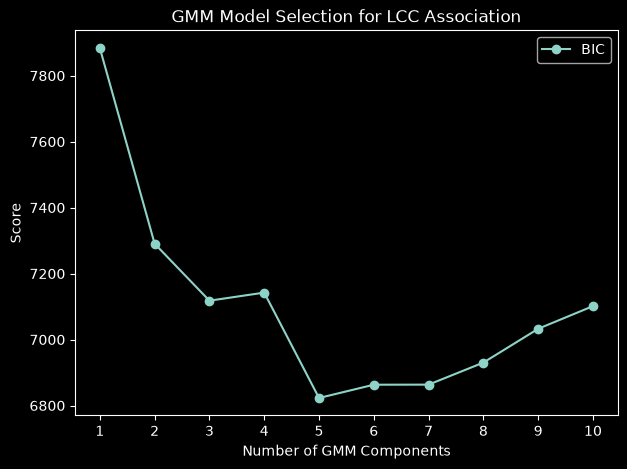

,"n_components n_components: int, default=1The number of mixture components.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to the method chosen to initialize theparameters (see `init_params`).In addition, it controls the generation of random samples from thefitted distribution (see the method `sample`).Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"covariance_type covariance_type: {'full', 'tied', 'diag', 'spherical'}, default='full'String describing the type of covariance parameters to use.Must be one of:- 'full': each component has its own general covariance matrix.- 'tied': all components share the same general covariance matrix.- 'diag': each component has its own diagonal covariance matrix.- 'spherical': each component has its own single variance.For an example of using `covariance_type`, refer to:ref:`sphx_glr_auto_examples_mixture_plot_gmm_selection.py`.",'full'
,"tol tol: float, default=1e-3The convergence threshold. EM iterations will stop when thelower bound average gain is below this threshold.",0.001
,"reg_covar reg_covar: float, default=1e-6Non-negative regularization added to the diagonal of covariance.Allows to assure that the covariance matrices are all positive.",1e-06
,"max_iter max_iter: int, default=100The number of EM iterations to perform.",100
,"n_init n_init: int, default=1The number of initializations to perform. The best results are kept.",1
,"init_params init_params: {'kmeans', 'k-means++', 'random', 'random_from_data'}, default='kmeans'The method used to initialize the weights, the means and theprecisions.String must be one of:- 'kmeans' : responsibilities are initialized using kmeans.- 'k-means++' : use the k-means++ method to initialize.- 'random' : responsibilities are initialized randomly.- 'random_from_data' : initial means are randomly selected data points... versionchanged:: v1.1 `init_params` now accepts 'random_from_data' and 'k-means++' as initialization methods.",'kmeans'
,"weights_init weights_init: array-like of shape (n_components, ), default=NoneThe user-provided initial weights.If it is None, weights are initialized using the `init_params` method.",None
,"means_init means_init: array-like of shape (n_components, n_features), default=NoneThe user-provided initial means,If it is None, means are initialized using the `init_params` method.",None
,"precisions_init precisions_init: array-like, default=NoneThe user-provided initial precisions (inverse of the covariancematrices).If it is None, precisions are initialized using the 'init_params'method.The shape depends on 'covariance_type':: (n_components,) if 'spherical', (n_features, n_features) if 'tied', (n_components, n_features) if 'diag', (n_components, n_features, n_features) if 'full'",None


In [15]:
n_components_range = range(1, 11)

bics = []

for n in n_components_range:

    gmm = GaussianMixture(
        n_components=n,
        covariance_type='full',
        random_state=42
    )

    gmm.fit(Xns_LCC)

    bics.append(gmm.bic(Xns_LCC))


best_n = n_components_range[np.argmin(bics)]

print(f"Best number of clusters according to BIC: {best_n}")


plt.figure(figsize=(7,5))

plt.plot(n_components_range, bics, marker='o', label='BIC')

plt.xlabel('Number of GMM Components')
plt.ylabel('Score')

plt.xticks(list(n_components_range))

plt.legend()

plt.title('GMM Model Selection for LCC Association')

plt.show()


best_gmm = GaussianMixture(
    n_components=best_n,
    covariance_type='full',
    random_state=42
)

best_gmm.fit(Xns_LCC)

Aquí ya calculamos la probabilidad de pertenencia ya sabiendo que el número de clusters recomendado según el BIC es de $n=5$.

In [16]:
gmm_LCC = GaussianMixture(
    n_components=5,
    covariance_type='full',
    random_state=42
    )

gmm_LCC.fit(Xns_LCC)

labels_LCC = gmm_LCC.predict(Xns_LCC)
probs_LCC = gmm_LCC.predict_proba(Xns_LCC)

Vamos a hacer una matriz de dispersión gráfica, aquí nos interesa ver aquellas estrellas que tienen los movimientos propios encerrados como en una burbujita, ya que entre más juntos quiere decir que sus movimientos propios son similares.

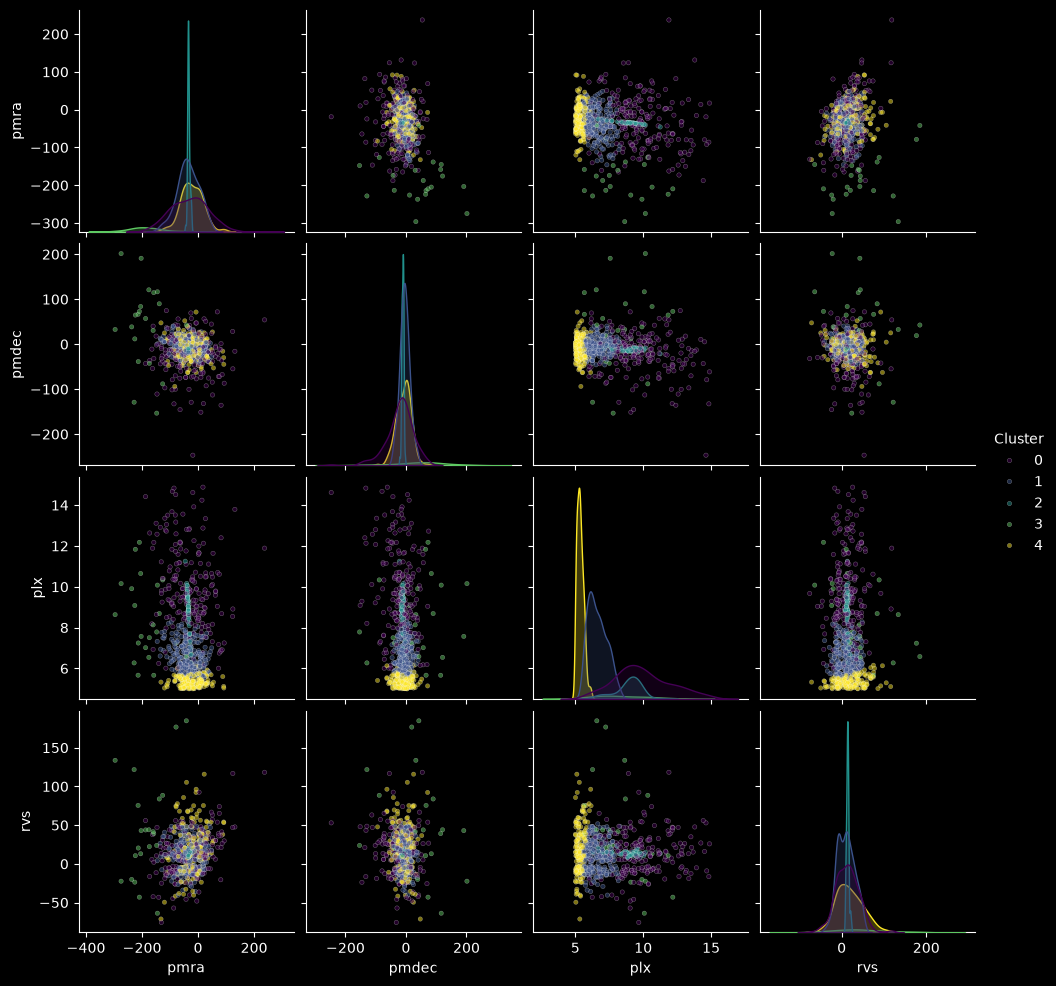

In [17]:
df_dataLCC = pd.DataFrame(
    Xs_LCC,
    columns=['pmra', 'pmdec', 'plx', 'rvs']
)

# Añadimos la columna 'Cluster' con las etiquetas obtenidas del modelo GMM
df_dataLCC['Cluster'] = labels_LCC

# Definimos los colores de los clusters:
# LCC_colors = {
#     0: 'blue',
#     1: 'magenta',
#     2:'blue',
# }
#plt.style.use('default')
# El pair plot va a recibir los datos y los va plotear en forma de una matriz.
sns.pairplot(
    df_dataLCC,
    hue='Cluster',
    diag_kind='kde',
    palette='viridis',
    vars=['pmra', 'pmdec', 'plx', 'rvs'],
    plot_kws={'alpha': 0.5, 's': 10}
)

plt.show()

Aquí ya lo que hacemos es tomar las estrellas que pertenecen al primer cluster, ya que estas como vemos en el `pairplot` de `Seaborn` son las más definidas para los movimientos propios y tienen coherencia con los demás campos que se están comparando.

In [18]:
mask_c2 = (probs_LCC[:,2] > 0.5)

datos_LCC = filtro_3_LCC[mask_c2]
print(len(datos_LCC))

59


## **Solución astrométrica**

Para calcular esta solución respecto al marco de referencia de La Tierra vamos a usar la siguiente función que reúne funciones y métodos de `astropy` para poder calcular las componentes cartesianas del cúmulo.

In [19]:
def cartesian_coordinates(resultado):
  dato_random = resultado['ra',
                         'dec',
                         'parallax',
                         'pmra',
                         'pmdec',
                         'radial_velocity']

  # Vamos a obtener los datos de movimiento propio, coordenadas
  # y además la velocidad radial:
  ra_rd = dato_random['ra'] * u.deg
  dec_rd = dato_random['dec'] * u.deg
  plx_rd = dato_random['parallax'] * u.mas
  pmra_rd = dato_random['pmra'] * (u.mas / u.yr)
  pmdec_rd = dato_random['pmdec'] * (u.mas / u.yr)
  rv_rd = dato_random['radial_velocity'] * u.km / u.s

  # Debemos obtener la distancia:
  dist_rd = plx_rd.to(u.pc, equivalencies=u.parallax())

  # Creamos un objeto skycoord:
  rd_skycc = SkyCoord(
    ra=ra_rd,
    dec=dec_rd,
    distance=dist_rd,
    pm_ra_cosdec=pmra_rd,
    pm_dec=pmdec_rd,
    radial_velocity=rv_rd
  )

  # Obtenemos la representación cartesiana
  cartesian_rd = rd_skycc.represent_as(CartesianRepresentation)

  # Coordenadas xyz:
  cartesian_xyz = cartesian_rd.xyz.value
  # Velocidades:
  cartesian_vs = cartesian_rd.differentials['s'].d_xyz.to(u.pc / u.Myr).value

  # Hacemos un súper vector:
  cartesian_all = np.concatenate((cartesian_xyz, cartesian_vs))

  return cartesian_all

Aquí obtenemos la solución cartesiana en forma de vecotres de estado de movimiento almacenados en una matriz de estado para LCC.

In [20]:
cartesian_LCC = np.zeros((len(datos_LCC), 6))

for i, cp in enumerate(datos_LCC):
  cartesian_LCC[i] = cartesian_coordinates(cp)

Si queremos verificar lo que vemos aquí tenemos un quiver tridimensional de nuestros vectores.

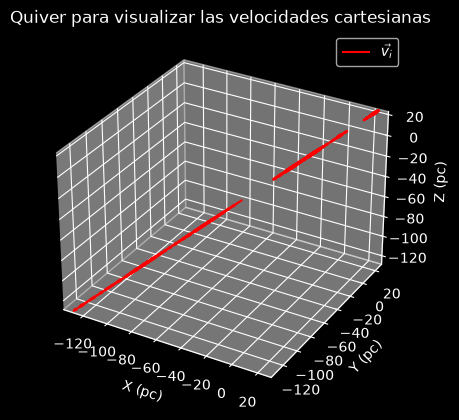

In [21]:
#subset = np.random.choice(len(cartesian_LCC), size=200, replace=False)

# Elejimos aleatoriamente las posiciones
x_subset = cartesian_LCC
y_subset = cartesian_LCC
z_subset = cartesian_LCC

# Así mismo con las velocidades:
vx_subset = cartesian_LCC
vy_subset = cartesian_LCC
vz_subset = cartesian_LCC

ax = plt.figure().add_subplot(projection='3d')

# Hacemos la maya con las posiciones:

ax.quiver(x_subset, y_subset, z_subset,
          vx_subset, vy_subset, vz_subset,
          length=10.0, normalize=True, color='red',
          label=r'$\vec{v_i}$')

ax.set_title("Quiver para visualizar las velocidades cartesianas")
ax.set_xlabel('X (pc)')
ax.set_ylabel('Y (pc)')
ax.set_zlabel('Z (pc)')
ax.legend(loc='best')

plt.show()

Ahora vamos a hacer el retroceso temporal, primero definiremos el tiempo de integración en la variable `ts` y de ahí aplicaremos el código de la siguiente celda que usa las ecuaciones del movimiento rectilíneo unifrome para obtener las posiciones y velocidades respectivas en el tiempo.

In [22]:
ts = np.linspace(0, -10, 100)

In [23]:
posiciones = cartesian_LCC[:,:3]
velocidades = cartesian_LCC[:,3:]
distancias = np.zeros((len(ts), len(posiciones)))

promedios = np.zeros((len(ts), 3))

pos_pasado = np.zeros((len(ts), len(posiciones), 3))

for i, t in enumerate(ts):
    # Calculamos las posiciones hacia atrás en el tiempo.
    pos_pasado[i] = posiciones + velocidades * t

    # Calculamos el centroide de cada tiempo:
    promedios[i] = np.mean(pos_pasado[i], axis=0) 

    # Calculamos las normas de cada vector de posición de las estrellas
    # en un momento del tiempo.
    distancias[i] = np.linalg.norm(pos_pasado[i] - promedios[i], axis=1)

# Calculamos la desviación estándar de las normas para luego
# comparar cuál es la mínima.
stds = np.std(distancias, axis=1)

print(distancias.shape)

(100, 59)


La hora de la verdad, calcular la edad cinemática en la aproximación lineal:

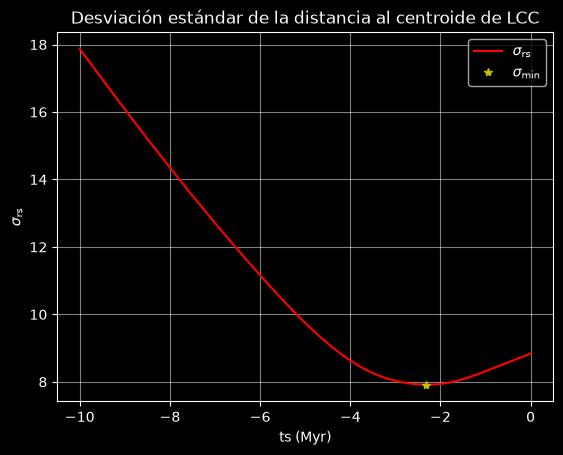

El mínimo de la desviación estándar ocurre en: -2.32 Myr


In [24]:
t_min_LCC = ts[np.argmin(stds)]
stds_min = stds[np.argmin(stds)]

plt.plot(ts, stds, 'r-', label=r'$\sigma_\text{rs}$')
plt.plot(t_min_LCC, stds_min, 'y*', label=r'$\sigma_\text{min}$')
plt.title("Desviación estándar de la distancia al centroide de LCC")
plt.legend(loc='best')
plt.xlabel('ts (Myr)')
plt.ylabel(r'$\sigma_\text{rs}$')
plt.grid(alpha=0.5)
plt.show()

print(f"El mínimo de la desviación estándar ocurre en: {t_min_LCC:.2f} Myr")

Bien podemos observar aquí que la dispersión de las medidas de las estrellas respecto al centroide, es decir la media muestral, es mínima en un punto. Por lo que quiere decir que la edad cinemática aproximada de esta asociación usando la aproximación lineal de velocidades con movimiento rectilíneo uniforme es de:

$$2.32 \ \text{Myr}$$

## **Nuevos miembros de LCC**

Como bien se solicitó, vamos a plotear los miembros de Simbad originalmente guardados vs los miembros que obtuvimos en este análisis con GMM y veremos qué cambios ocurrieron.

Para esto haremos un sencillo gráfico de scatter de asención recta y declinación.

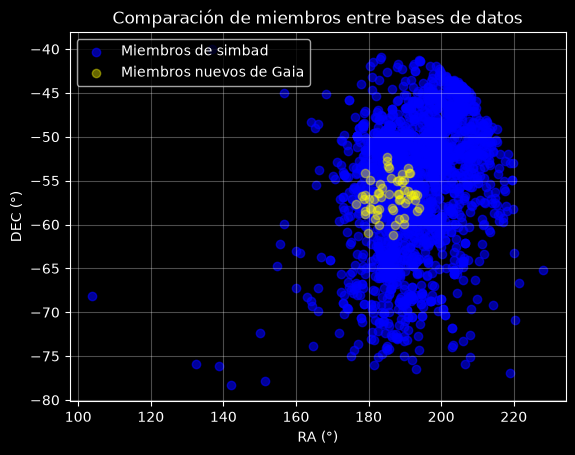

In [25]:
plt.scatter(simbad_LCC['RA_d'], simbad_LCC['DEC_d'], 
            color='blue', alpha=0.6, label='Miembros de simbad')
plt.scatter(datos_LCC['ra'], datos_LCC['dec'],
            color='yellow', alpha=0.4, label='Miembros nuevos de Gaia')

plt.title('Comparación de miembros entre bases de datos')
plt.legend(loc='best')
plt.xlabel('RA (°)')
plt.ylabel("DEC (°)")
plt.grid(alpha=0.3)
plt.show()

Aquí el resultado no es muy satisfactorio, debido a los pocos datos que traía el query y debido a que fueron seleccionados apenas en una región de $5°$ de radio con especificaciones muy estrictas.

Lo anterior fue para poder obtener estrellas relavantes del cúmulo ya que GAIA contiene millones de datos de estrellas y muchas de ellas son estrellas de campo, que cuando se hizo el análisis en una región más grande se encontró que no hubo convergencia para los datos y la edad cinemática falló.

Ahora bien a pesar de ser una muestra en una región más reducida, podemos decir que la aproximación de la edad cinemática está sesgada ya que no consideramos un radio más amplio.

# **TW Hydrae Association**

TW HYdrae Association es un cúmulo abierto cercano al Sistema Solar, entre 25 y 75 pc de distancia. Sus miembros están muyr regados y dispersos ya que según la literatura su edad ronda por los 10.3 Myr. Está ubicada hacia la constelación de Hydra y según simbad cuenta con 280 miembros principales.

In [26]:
simbad_TW= Table.read('TW_hydrae_simbad.vot', format='votable')

Para restringir nuestro query en Gaia vamos a analizar los paralajes de los miembros de TW Hydrae, descartamos primero aquellos que son muy grandes y aquellos que son muy chiquitos y según el siguiente gráfico podemos ver que las estrellas de éste cúmulo están concentradas en una región entre 10 y 40 mas.

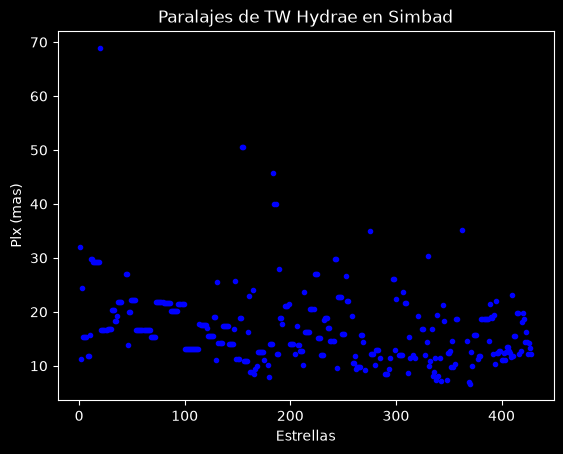

In [27]:
plxs_TW = simbad_TW['PLX_VALUE'].data

plt.plot(plxs_TW, 'b.')
plt.title('Paralajes de TW Hydrae en Simbad')
plt.xlabel('Estrellas')
plt.ylabel('Plx (mas)')
plt.show()

Según la literatura, tenemos que TW Hydrae está entre 25 y 120 pc de distancia, es decir sus miembros están repartidos a esas distancias de nuestro Sistema Solar.

Con esto en cuenta podemos ahora sí molestar a Gaia y una vez hecho el query tenemos los siguientes datos almacenados aquí:

In [28]:
ra_TW = sex2dec(11,1,54) * 15
print(f"RA: {ra_TW}°")

dec_TW = sex2dec(-34,42,0)
print(f"dec: {dec_TW}°")

RA: 165.47500000000002°
dec: -34.7°


Este fue el query que hicimos a Gaia, está comentado para no tener que recurrir a que el servicio responda y hacer las descargas.

In [29]:
# query_TW = f"""
# SELECT TOP 6000
# source_id,
# ra,
# dec,
# parallax,
# parallax_over_error AS plx_oerr,
# pmra,
# pmra_error,
# pmdec,
# pmdec_error,
# phot_g_mean_mag,
# radial_velocity,
# radial_velocity_error AS rv_error
# FROM gaiadr3.gaia_source
# WHERE CONTAINS(POINT('ICRS', ra, dec), CIRCLE('ICRS', {ra_TW}, {dec_TW}, 20.0)) = 1
# AND parallax >= 13 AND parallax <= 40
# AND pmra IS NOT NULL
# AND pmdec IS NOT NULL
# AND phot_g_mean_mag < 14.0
# AND radial_velocity IS NOT NULL
# """

# job_TW = Gaia.launch_job(query_TW)
# result_TW = job_TW.get_results()

Para poder trabajar con los datos, guardamos el resultado en un archivo fits.

In [30]:
# Guarda la tabla como un archivo binario FITS
#result_TW.write('tw_cartesian_data.fits', format='fits', overwrite=True)

Aquí tenemos los resultados del query, vamos entonces a hacer el mismo procedimiento que anteriormente hicimos para LCC.

In [31]:
result_TW = Table.read('tw_cartesian_data.fits', format='fits')

Aquí podemos ver una comparación entre los miembros de TW Hydrae catalogados en Simbad vs las estrellas que tiene Gaia registradas en su base de datos.

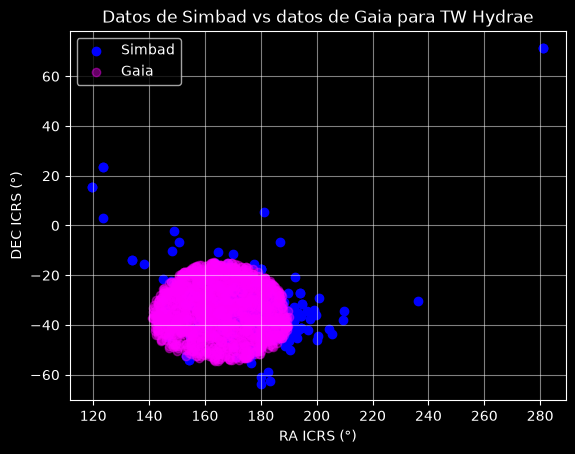

In [32]:
plt.scatter(simbad_TW['RA_d'], simbad_TW['DEC_d'], color='blue', alpha=1.0, label='Simbad')
plt.scatter(result_TW['ra'], result_TW['dec'], color='magenta', alpha=0.4, label='Gaia')
plt.title('Datos de Simbad vs datos de Gaia para TW Hydrae')
plt.legend()
plt.xlabel('RA ICRS (°)')
plt.ylabel('DEC ICRS (°)')
plt.grid(alpha=0.5)
plt.show()

## **Filtrado por errores**

Vamos a tomar los mismos parámetros: movimientos propios, paralajes y velocidades radiales.

Iniciamos nuevamente con los paralajes, queremos tener una $S/N > 0$ con la columna del error relativo como señal ruido.

In [33]:
mask_TW_plx = result_TW['plx_oerr'] > 10

filtro_1_TW = result_TW[mask_TW_plx]
print(len(result_TW), len(filtro_1_TW))

1699 1699


Con el filtro de los movimientos propios vamos a ser un poco más estrictos por su cercanía a La Tierra, debe ser menor que 0.1

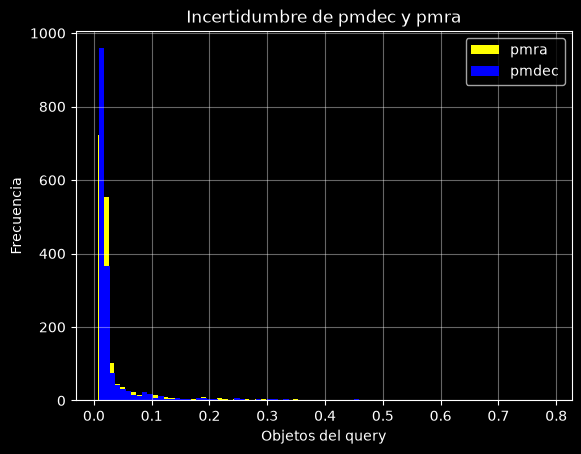

In [34]:
plt.hist(result_TW['pmra_error'], bins='auto', color='yellow', label='pmra')
plt.hist(result_TW['pmdec_error'], bins='auto', color='blue', label='pmdec')
plt.legend()
plt.title("Incertidumbre de pmdec y pmra")
plt.xlabel('Objetos del query')
plt.ylabel('Frecuencia')
plt.grid(alpha=0.4)
plt.show()

Con el anterior histograma podemos ver que la mayoría de los datos tiene una incertidumbre muy baja, para eliminar outliers la icertidumbre que mejor se ajusta debería ser menor a 0.05, siendo éste valor la cota máxima.

In [35]:
mask_pm_TW = (filtro_1_TW['pmra_error'] < 0.05) & (filtro_1_TW['pmdec_error'] < 0.05)

filtro_2_TW = filtro_1_TW[mask_pm_TW]
len(filtro_2_TW)

1435

### **Filtro por velocidad radial**

Queremos analizar un error relativo, por lo que definimos éste como:

$$\text{Error relativo} = \frac{\text{Error absoluto}}{\text{Valor}}$$

Conservamos el mismo umbral de que sea menos del 20\%

In [36]:
errores_rv_TW = np.abs(filtro_2_TW['rv_error'].data / filtro_2_TW['radial_velocity'].data)

# Aquí la máscara para tomar los valores.
mask3_TW = errores_rv_TW <= 0.2

filtro_3_TW = filtro_2_TW[mask3_TW]

len(filtro_3_TW)

1233

## **Método de Gaussian Mixtures para TW Hydrae**

Aquí nuevamente vamos a normalizar los datos, ya que tenemos un espacio 4-dimensional con tres cosas medidas en miliarcosegundos (mas) y la velocidad radial en km/s.

In [37]:
Xs_TW = np.column_stack(
    [filtro_3_TW['pmra'], filtro_3_TW['pmdec'], 
     filtro_3_TW['parallax'], filtro_3_TW['radial_velocity']]
)

# Aplicamos la normalización a gaussianas estándar.
scaler = StandardScaler()
Xns_TW = scaler.fit_transform(Xs_TW)

Utilizando el código disponible del respositorio de GitHub del curso de Minería de Datos del pregrado de Astronomía de la Universidad de Antioquia nuevamente, vamos a calcular cuántos clusters idealmente serían los requeridos para nuestro espacio 4D de parámetros que estamos manejando.

Best number of clusters according to BIC: 3


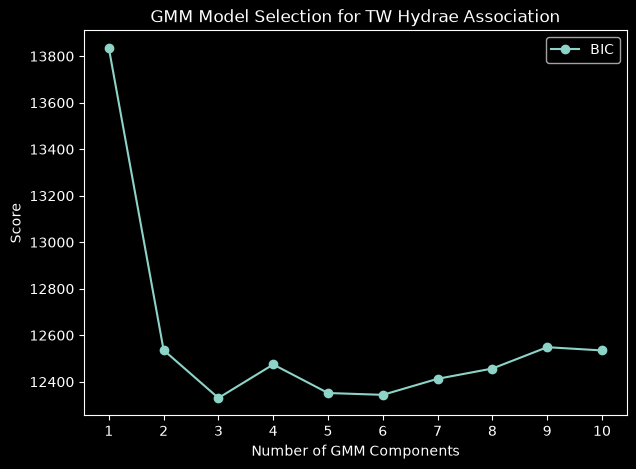

,"n_components n_components: int, default=1The number of mixture components.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to the method chosen to initialize theparameters (see `init_params`).In addition, it controls the generation of random samples from thefitted distribution (see the method `sample`).Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"covariance_type covariance_type: {'full', 'tied', 'diag', 'spherical'}, default='full'String describing the type of covariance parameters to use.Must be one of:- 'full': each component has its own general covariance matrix.- 'tied': all components share the same general covariance matrix.- 'diag': each component has its own diagonal covariance matrix.- 'spherical': each component has its own single variance.For an example of using `covariance_type`, refer to:ref:`sphx_glr_auto_examples_mixture_plot_gmm_selection.py`.",'full'
,"tol tol: float, default=1e-3The convergence threshold. EM iterations will stop when thelower bound average gain is below this threshold.",0.001
,"reg_covar reg_covar: float, default=1e-6Non-negative regularization added to the diagonal of covariance.Allows to assure that the covariance matrices are all positive.",1e-06
,"max_iter max_iter: int, default=100The number of EM iterations to perform.",100
,"n_init n_init: int, default=1The number of initializations to perform. The best results are kept.",1
,"init_params init_params: {'kmeans', 'k-means++', 'random', 'random_from_data'}, default='kmeans'The method used to initialize the weights, the means and theprecisions.String must be one of:- 'kmeans' : responsibilities are initialized using kmeans.- 'k-means++' : use the k-means++ method to initialize.- 'random' : responsibilities are initialized randomly.- 'random_from_data' : initial means are randomly selected data points... versionchanged:: v1.1 `init_params` now accepts 'random_from_data' and 'k-means++' as initialization methods.",'kmeans'
,"weights_init weights_init: array-like of shape (n_components, ), default=NoneThe user-provided initial weights.If it is None, weights are initialized using the `init_params` method.",None
,"means_init means_init: array-like of shape (n_components, n_features), default=NoneThe user-provided initial means,If it is None, means are initialized using the `init_params` method.",None
,"precisions_init precisions_init: array-like, default=NoneThe user-provided initial precisions (inverse of the covariancematrices).If it is None, precisions are initialized using the 'init_params'method.The shape depends on 'covariance_type':: (n_components,) if 'spherical', (n_features, n_features) if 'tied', (n_components, n_features) if 'diag', (n_components, n_features, n_features) if 'full'",None


In [38]:
n_components_range = range(1, 11)

bics = []

for n in n_components_range:

    gmm = GaussianMixture(
        n_components=n,
        covariance_type='full',
        random_state=42
    )

    gmm.fit(Xns_TW)

    bics.append(gmm.bic(Xns_TW))


best_n = n_components_range[np.argmin(bics)]

print(f"Best number of clusters according to BIC: {best_n}")


plt.figure(figsize=(7,5))

plt.plot(n_components_range, bics, marker='o', label='BIC')

plt.xlabel('Number of GMM Components')
plt.ylabel('Score')

plt.xticks(list(n_components_range))

plt.legend()

plt.title('GMM Model Selection for TW Hydrae Association')

plt.show()


best_gmm = GaussianMixture(
    n_components=best_n,
    covariance_type='full',
    random_state=42
)

best_gmm.fit(Xns_TW)

Luego calculamos las probabilidades de pertenencia a los clusters.

In [39]:
# Aquí aplicamos el modelo y calculamos probabilidades
# de pertenencia a los clusters
gmm_TW = GaussianMixture(
    n_components=3,
    covariance_type='full',
    random_state=42
    )

gmm_TW.fit(Xns_TW)

labels_TW = gmm_TW.predict(Xns_TW)
probs_TW = gmm_TW.predict_proba(Xns_TW)

print(probs_TW)

[[8.71287031e-01 7.05386998e-09 1.28712962e-01]
 [9.78913386e-01 5.85421842e-03 1.52323954e-02]
 [4.46878736e-01 5.50839078e-01 2.28218687e-03]
 ...
 [9.99943374e-02 8.99664219e-01 3.41443636e-04]
 [9.78795073e-01 6.64485015e-03 1.45600764e-02]
 [3.89422713e-02 9.60905419e-01 1.52309239e-04]]


Vamos a visualizar qué cluster representa mejor a los miembros potenciales del cúmulo abierto de TW Hydrae que trajimos de Gaia.

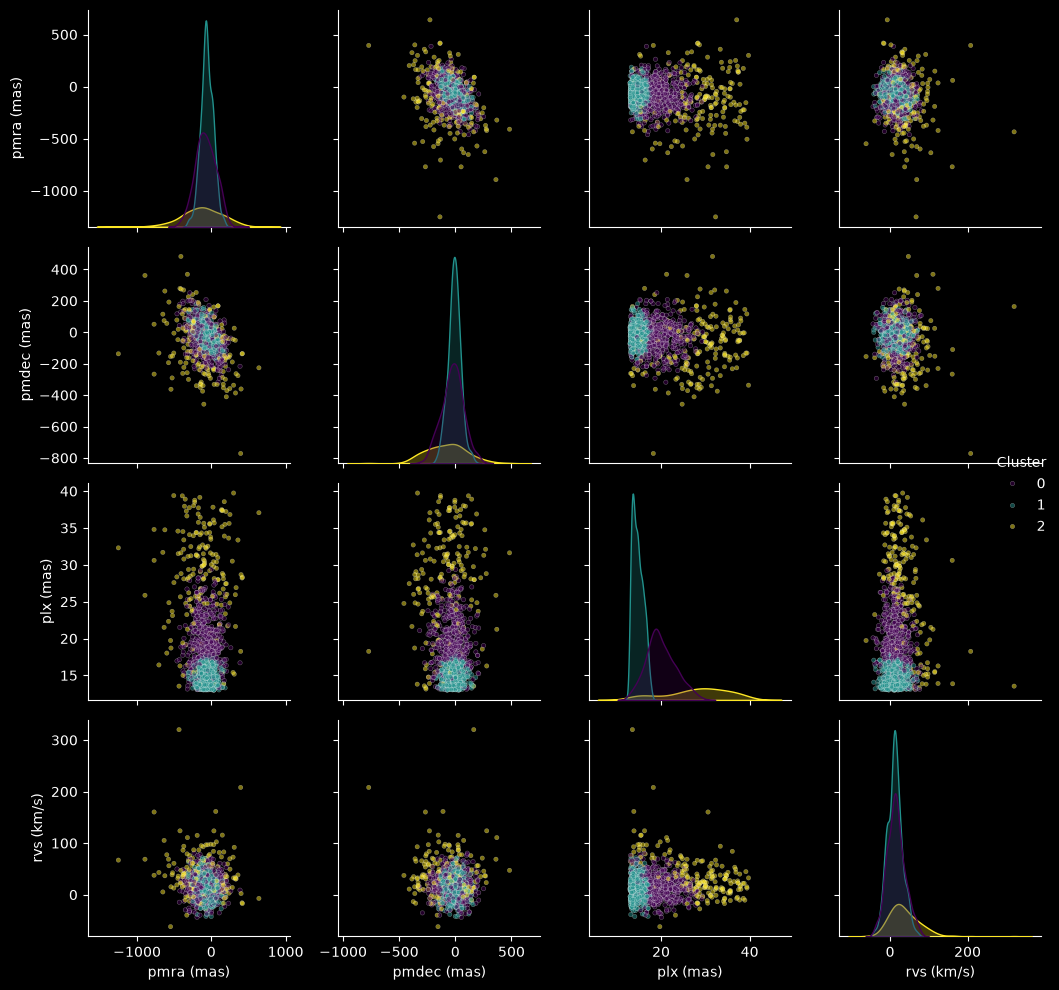

In [40]:
df_dataTW = pd.DataFrame(
    Xs_TW,
    columns=['pmra (mas)', 'pmdec (mas)', 'plx (mas)', 'rvs (km/s)']
)

# Añadimos la columna 'Cluster' con las etiquetas obtenidas del modelo GMM
df_dataTW['Cluster'] = labels_TW

# El pair plot va a recibir los datos y los va plotear en forma de una matriz.
sns.pairplot(
    df_dataTW,
    hue='Cluster',
    diag_kind='kde',
    palette='viridis',
    vars=['pmra (mas)', 'pmdec (mas)', 'plx (mas)', 'rvs (km/s)'],
    plot_kws={'alpha': 0.5, 's': 10}
)

plt.tight_layout()
plt.show()

Aplicamos el umbral de pertenencia sea del 0.7 (de probabilidad) en adelante.

In [41]:
mask_c0 = (probs_TW[:,1] > 0.7)

datos_TW = filtro_3_TW[mask_c0]
len(datos_TW)

485

## **Solución astrométrica**

Así como para LCC, vamos a repetir la solución astrométrica con la función que habíamos definido antes.

In [42]:
cartesian_TW = np.zeros((len(datos_TW), 6))

for i, cp in enumerate(datos_TW):
  cartesian_TW[i] = cartesian_coordinates(cp)

Si se quiere visualizar las estrellas del cluster óptimo y su distribución en el espacio con sus velocidades aquí está este quiver.

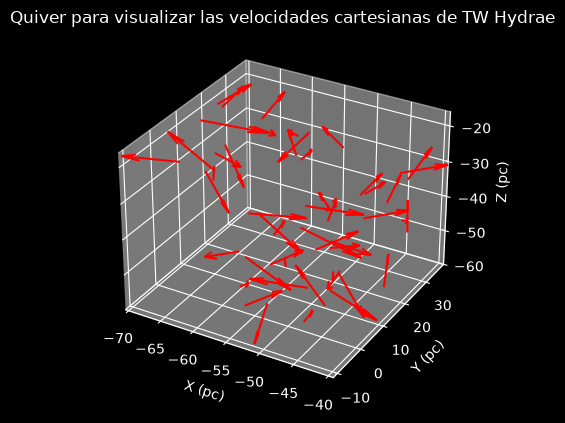

In [43]:
subset_TW = np.random.choice(len(cartesian_TW), size=50, replace=False)

# Elejimos aleatoriamente las posiciones
x_subset_TW = cartesian_TW[:,0][subset_TW]
y_subset_TW = cartesian_TW[:,1][subset_TW]
z_subset_TW = cartesian_TW[:,2][subset_TW]

# Así mismo con las velocidades:
vx_subset_TW = cartesian_TW[:,3][subset_TW]
vy_subset_TW = cartesian_TW[:,4][subset_TW]
vz_subset_TW = cartesian_TW[:,5][subset_TW]

ax = plt.figure().add_subplot(projection='3d')

# Hacemos la maya con las posiciones:

ax.quiver(x_subset_TW, y_subset_TW, z_subset_TW,
          vx_subset_TW, vy_subset_TW, vz_subset_TW,
          length=10.0, normalize=True, color='red')

ax.set_title("Quiver para visualizar las velocidades cartesianas de TW Hydrae")
ax.set_xlabel('X (pc)')
ax.set_ylabel('Y (pc)')
ax.set_zlabel('Z (pc)')

plt.show()

Calculamos el tracback de las estrellas.

In [44]:
ts = np.linspace(0, -10, 100)

posiciones_TW = cartesian_TW[:,:3]
velocidades_TW = cartesian_TW[:,3:]
distancias_TW = np.zeros((len(ts), len(posiciones_TW)))

promedios_TW = np.zeros((len(ts), 3))

pos_pasado_TW = np.zeros((len(ts), len(posiciones_TW), 3))

for i, t in enumerate(ts):
    # Calculamos las posiciones_TW hacia atrás en el tiempo.
    pos_pasado_TW[i] = posiciones_TW + velocidades_TW * t

    # Calculamos el centroide de cada tiempo:
    promedios_TW[i] = np.mean(pos_pasado_TW[i], axis=0) 

    # Calculamos las normas de cada vector de posición de las estrellas
    # en un momento del tiempo.
    distancias_TW[i] = np.linalg.norm(pos_pasado_TW[i] - promedios_TW[i], axis=1)

# Calculamos la desviación estándar de las normas para luego
# comparar cuál es la mínima.
stds_TW = np.std(distancias_TW, axis=1)

print(distancias_TW.shape)

(100, 485)


A diferencia de la agrupación anterior y de los análisis realizados aquí con el Gaussian Mixtures Models vemos que no logró encontrar una edad cinemática concreta para esta agrupación.

Posibles razones:

- Ruido de las estrellas de fondo: en los datos deben haber muchas estrellas de fondo cercanas con valores de los parámetros del espacio 4-dimensional que elegimos los cuales juegan en contra a la hora de pedirle a la máquina que clasifique por clusters los datos.

- Pocos miembros, muchos intrusos. En gaia las estrellas de este cúmulo pueden ser poco brillantes y si pasan el umbral de $G > 14.0$, en magnitud visible, la velocidad radial no estará disponible y tendremos entonces estrellas intrusas en vez de estrellas del cúmulo.

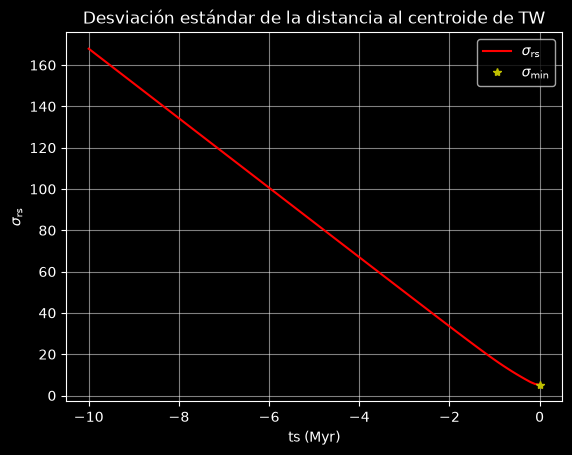

El mínimo de la desviación estándar ocurre en: 0.00 Myr


In [45]:
t_min_TW = ts[np.argmin(stds_TW)]
stds_TW_min = stds_TW[np.argmin(stds_TW)]

plt.plot(ts, stds_TW, 'r-', label=r'$\sigma_\text{rs}$')
plt.plot(t_min_TW, stds_TW_min, 'y*', label=r'$\sigma_\text{min}$')
plt.title("Desviación estándar de la distancia al centroide de TW")
plt.legend(loc='best')
plt.xlabel('ts (Myr)')
plt.ylabel(r'$\sigma_\text{rs}$')
plt.grid(alpha=0.5)
plt.show()

print(f"El mínimo de la desviación estándar ocurre en: {t_min_TW:.2f} Myr")

# **Upper Centaurus-Lupus Association**

La última asociación estelar que va a tener este proyecto es Upper Centaurus-Lupus, parte de la gran asociación estelar de Upper Scorpius, siendo esta la asociación de estrellas jóvenes más cercana al Sistema Solar. Este grupo está compuesto por estrellas jóvenes azules que tienen apenas una edad de 18 Myr.

In [46]:
simbad_UCL = Table.read('simbad_UCL.vot', format='votable')
#simbad_UCL

Aquí tenemos los valores de paralaje que nos entrega Simbad, vamos a aprovecharlos para ver dónde se concentra más la asociación UCL. Según el gráfico que a continuación puede verse, al igual que Lower Centaurus-Crux, las estrellas de Upper Centaurus-Lupus están en un rango de entre 5 mas y 15 mas.

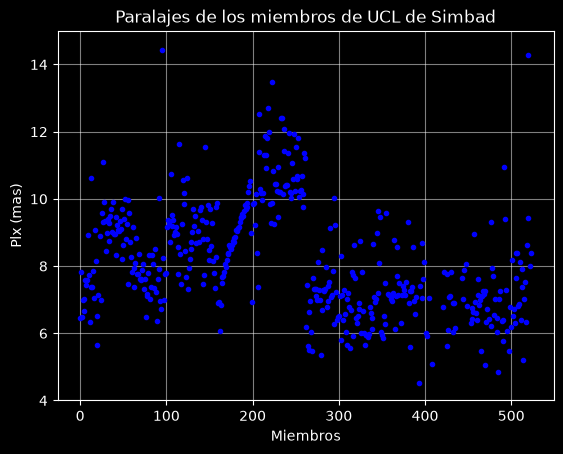

In [47]:
plxs_ucl = simbad_UCL['PLX_VALUE'].data

plt.style.use('dark_background')

plt.plot(plxs_ucl, 'b.')
plt.title('Paralajes de los miembros de UCL de Simbad')
plt.xlabel('Miembros')
plt.ylabel('Plx (mas)')
plt.ylim(4, 15)
plt.grid(alpha=0.5)
plt.show()

Con lo anterior en mente, va a tomarse en el query a Gaia esta restricción para hacer el cross-match con los datos que vamos a pedir en un cone-search alrededor de la región central de UCL que según Simbad tiene coordenadas:

$$\alpha_\text{ICRS} = [15 hr, 24 min, 00 sec]$$
$$\delta_\text{ICRS} = [-41°, 54', 00'']$$

In [48]:
ra_UCL = sex2dec(15,24,0) * 15
print(f"RA: {ra_UCL}°")

dec_UCL = sex2dec(-41,54,0)
print(f"dec: {dec_UCL}°")

RA: 231.0°
dec: -41.9°


In [49]:
# query_UCL = f"""
# SELECT TOP 10000
# source_id,
# ra,
# ra_error,
# dec,
# dec_error,
# parallax,
# parallax_over_error AS plx_oerr,
# pmra,
# pmra_error,
# pmdec,
# pmdec_error,
# phot_g_mean_mag,
# radial_velocity,
# radial_velocity_error AS rv_error
# FROM gaiadr3.gaia_source
# WHERE CONTAINS(POINT('ICRS', ra, dec), CIRCLE('ICRS', {ra_UCL}, {dec_UCL}, 8.0)) = 1
# AND parallax >= 4 AND parallax < 15
# AND pmra IS NOT NULL
# AND pmdec IS NOT NULL
# AND phot_g_mean_mag < 14.0
# AND radial_velocity IS NOT NULL
# """

# job_UCL = Gaia.launch_job(query_UCL)
# result_UCL = job_UCL.get_results()

In [50]:
#result_UCL.write('gaia_UCL.fits', format='fits', overwrite=True)

Aquí cargamos el resultado de nuestro query realizado a Gaia para Upper Centaurus-Lupus association, aquí elegimos un radio un poco más grande para esta asociación y definimos en el query anterior todos aquellos parámetros para que obtengamos mejor filtradas las velocidades radiales y paralajes no nulos o negativos.

In [51]:
gaia_UCL = Table.read('gaia_UCL.fits', format='fits')

Veamos la comparativa de miembros de Upper Centaurus-Lupus entre Simbad y Gaia.

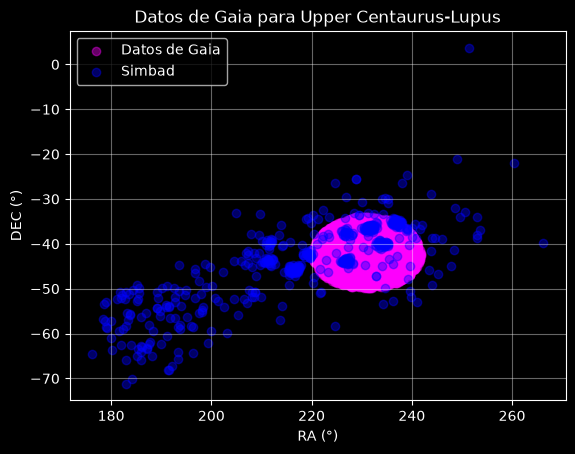

In [52]:
plt.scatter(gaia_UCL['ra'], gaia_UCL['dec'], color='magenta', alpha=0.4, label='Datos de Gaia')
plt.scatter(simbad_UCL['RA_d'], simbad_UCL['DEC_d'], color='blue', alpha=0.4, label='Simbad')
plt.title('Datos de Gaia para Upper Centaurus-Lupus')
plt.legend(loc='best')
plt.xlabel('RA (°)')
plt.ylabel('DEC (°)')
plt.grid(alpha=0.4)
plt.show()

## **Filtro por paralajes:**

In [53]:
mask_UCL_plx = gaia_UCL['plx_oerr'] > 10

filtro_1_UCL = gaia_UCL[mask_UCL_plx]
print(len(gaia_UCL), len(filtro_1_UCL))

4562 4531


## **Filtro por movimientos propios:**

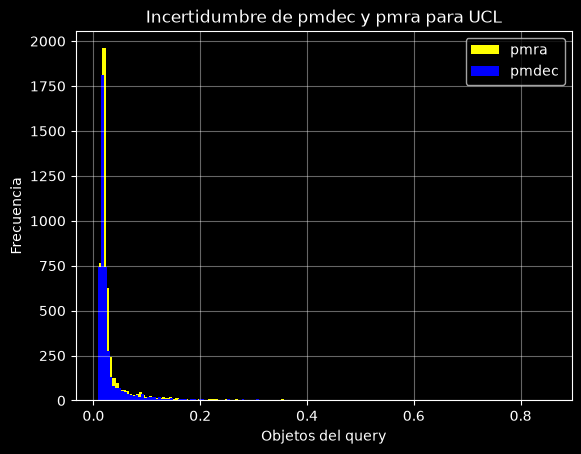

In [54]:
plt.hist(gaia_UCL['pmra_error'], bins='auto', color='yellow', label='pmra')
plt.hist(gaia_UCL['pmdec_error'], bins='auto', color='blue', label='pmdec')
plt.legend()
plt.title("Incertidumbre de pmdec y pmra para UCL")
plt.xlabel('Objetos del query')
plt.ylabel('Frecuencia')
plt.grid(alpha=0.4)
plt.show()

In [55]:
mask_pm_UCL = (filtro_1_UCL['pmra_error'] < 0.05) & (filtro_1_UCL['pmdec_error'] < 0.05)

filtro_2_UCL = filtro_1_UCL[mask_pm_UCL]
len(filtro_2_UCL)

3820

## **Filtro para velocidades radiales**

In [56]:
errores_rv_UCL = np.abs(filtro_2_UCL['rv_error'].data / filtro_2_UCL['radial_velocity'].data)

# Aquí la máscara para tomar los valores.
mask3_UCL = errores_rv_UCL <= 0.2

filtro_3_UCL = filtro_2_UCL[mask3_UCL]

len(filtro_3_UCL)

2987

Calculamos la probabilidad de pertenecer a un cluster.

In [57]:
Xs_UCL = np.column_stack(
    [filtro_3_UCL['pmra'], filtro_3_UCL['pmdec'], 
     filtro_3_UCL['parallax'], filtro_3_UCL['radial_velocity']]
)

# Aplicamos la normalización a gaussianas estándar.
scaler = StandardScaler()
Xns_UCL = scaler.fit_transform(Xs_UCL)

Calculamos el número de clusters recomendados por el BIC:

Best number of clusters according to BIC: 5


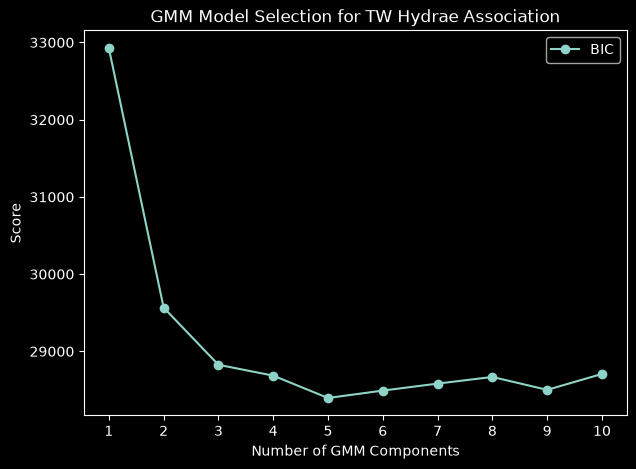

,"n_components n_components: int, default=1The number of mixture components.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to the method chosen to initialize theparameters (see `init_params`).In addition, it controls the generation of random samples from thefitted distribution (see the method `sample`).Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"covariance_type covariance_type: {'full', 'tied', 'diag', 'spherical'}, default='full'String describing the type of covariance parameters to use.Must be one of:- 'full': each component has its own general covariance matrix.- 'tied': all components share the same general covariance matrix.- 'diag': each component has its own diagonal covariance matrix.- 'spherical': each component has its own single variance.For an example of using `covariance_type`, refer to:ref:`sphx_glr_auto_examples_mixture_plot_gmm_selection.py`.",'full'
,"tol tol: float, default=1e-3The convergence threshold. EM iterations will stop when thelower bound average gain is below this threshold.",0.001
,"reg_covar reg_covar: float, default=1e-6Non-negative regularization added to the diagonal of covariance.Allows to assure that the covariance matrices are all positive.",1e-06
,"max_iter max_iter: int, default=100The number of EM iterations to perform.",100
,"n_init n_init: int, default=1The number of initializations to perform. The best results are kept.",1
,"init_params init_params: {'kmeans', 'k-means++', 'random', 'random_from_data'}, default='kmeans'The method used to initialize the weights, the means and theprecisions.String must be one of:- 'kmeans' : responsibilities are initialized using kmeans.- 'k-means++' : use the k-means++ method to initialize.- 'random' : responsibilities are initialized randomly.- 'random_from_data' : initial means are randomly selected data points... versionchanged:: v1.1 `init_params` now accepts 'random_from_data' and 'k-means++' as initialization methods.",'kmeans'
,"weights_init weights_init: array-like of shape (n_components, ), default=NoneThe user-provided initial weights.If it is None, weights are initialized using the `init_params` method.",None
,"means_init means_init: array-like of shape (n_components, n_features), default=NoneThe user-provided initial means,If it is None, means are initialized using the `init_params` method.",None
,"precisions_init precisions_init: array-like, default=NoneThe user-provided initial precisions (inverse of the covariancematrices).If it is None, precisions are initialized using the 'init_params'method.The shape depends on 'covariance_type':: (n_components,) if 'spherical', (n_features, n_features) if 'tied', (n_components, n_features) if 'diag', (n_components, n_features, n_features) if 'full'",None


In [58]:
n_components_range = range(1, 11)

bics = []

for n in n_components_range:

    gmm = GaussianMixture(
        n_components=n,
        covariance_type='full',
        random_state=42
    )

    gmm.fit(Xns_UCL)

    bics.append(gmm.bic(Xns_UCL))


best_n = n_components_range[np.argmin(bics)]

print(f"Best number of clusters according to BIC: {best_n}")


plt.figure(figsize=(7,5))

plt.plot(n_components_range, bics, marker='o', label='BIC')

plt.xlabel('Number of GMM Components')
plt.ylabel('Score')

plt.xticks(list(n_components_range))

plt.legend()

plt.title('GMM Model Selection for TW Hydrae Association')

plt.show()


best_gmm = GaussianMixture(
    n_components=best_n,
    covariance_type='full',
    random_state=42
)

best_gmm.fit(Xns_UCL)

In [59]:
# Aquí aplicamos el modelo y calculamos probabilidades
# de pertenencia a los clusters
gmm_UCL = GaussianMixture(
    n_components=5,
    covariance_type='full',
    random_state=42
    )

gmm_UCL.fit(Xns_UCL)

labels_UCL = gmm_UCL.predict(Xns_UCL)
probs_UCL = gmm_UCL.predict_proba(Xns_UCL)

Vamos a ver en un pairplot los clusters e identificar el mejor.

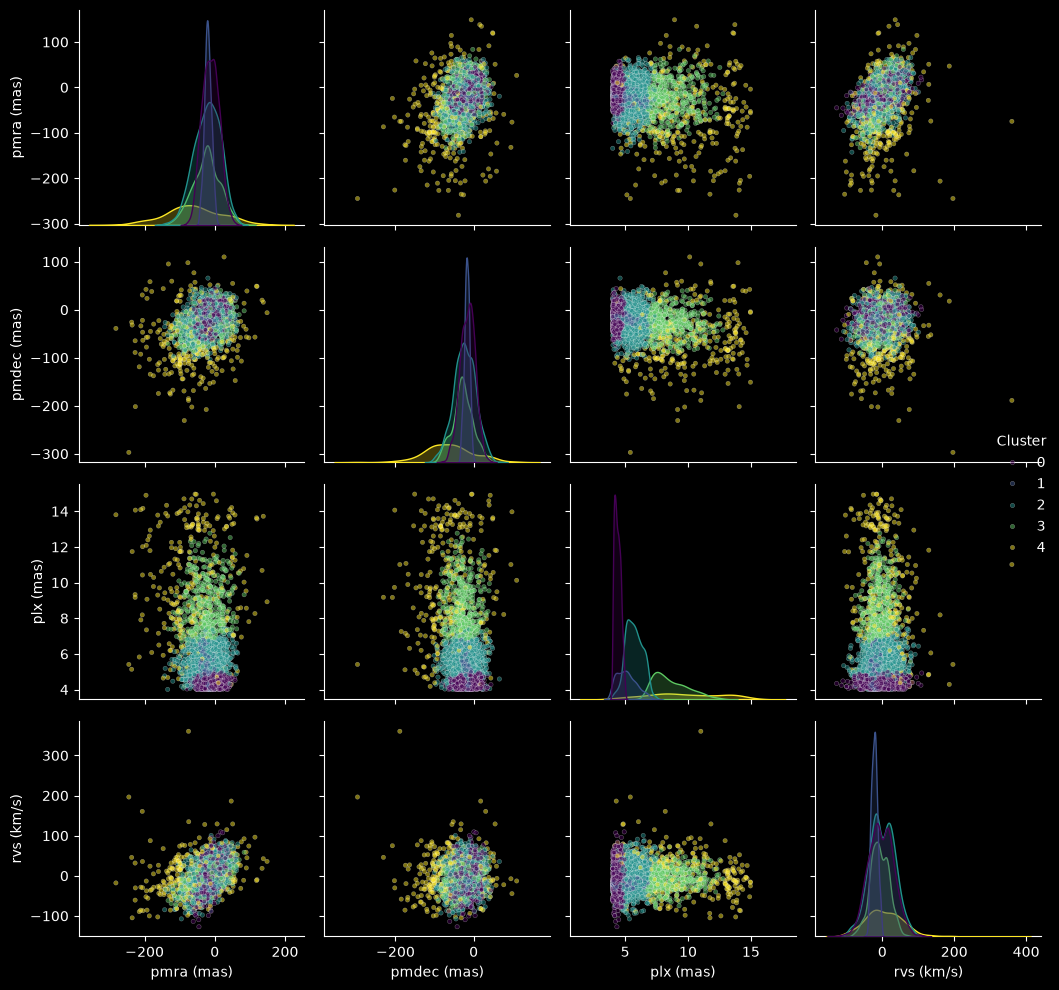

In [62]:
df_dataUCL = pd.DataFrame(
    Xs_UCL,
    columns=['pmra (mas)', 'pmdec (mas)', 'plx (mas)', 'rvs (km/s)']
)

# Añadimos la columna 'Cluster' con las etiquetas obtenidas del modelo GMM
df_dataUCL['Cluster'] = labels_UCL

plt.style.use('dark_background')

# El pair plot va a recibir los datos y los va plotear en forma de una matriz.
sns.pairplot(
    df_dataUCL,
    hue='Cluster',
    diag_kind='kde',
    palette='viridis',
    vars=['pmra (mas)', 'pmdec (mas)', 'plx (mas)', 'rvs (km/s)'],
    plot_kws={'alpha': 0.5, 's': 10}
)

plt.tight_layout()
plt.show()

Aquí podemos ver que el cluster que mejor agrupa los datos de las estrellas del cúmulo es el cluster 2

In [173]:
mask_c2_UCL = (probs_UCL[:,0] > 0.8)

datos_UCL = filtro_3_UCL[mask_c2_UCL]
len(datos_UCL)

582

## **Solución astrométrica**

In [174]:
cartesian_UCL = np.zeros((len(datos_UCL), 6))

for i, cp in enumerate(datos_UCL):
  cartesian_UCL[i] = cartesian_coordinates(cp)

In [175]:
ts = np.linspace(0, -15, 200)

posiciones_UCL = cartesian_UCL[:,:3]
velocidades_UCL = cartesian_UCL[:,3:]
distancias_UCL = np.zeros((len(ts), len(posiciones_UCL)))

promedios_UCL = np.zeros((len(ts), 3))

pos_pasado_UCL = np.zeros((len(ts), len(posiciones_UCL), 3))

for i, t in enumerate(ts):
    # Calculamos las posiciones_UCL hacia atrás en el tiempo.
    pos_pasado_UCL[i] = posiciones_UCL + velocidades_UCL * t

    # Calculamos el centroide de cada tiempo:
    promedios_UCL[i] = np.mean(pos_pasado_UCL[i], axis=0) 

    # Calculamos las normas de cada vector de posición de las estrellas
    # en un momento del tiempo.
    distancias_UCL[i] = np.linalg.norm(pos_pasado_UCL[i] - promedios_UCL[i], axis=1)

# Calculamos la desviación estándar de las normas para luego
# comparar cuál es la mínima.
stds_UCL = np.std(distancias_UCL, axis=1)

print(distancias_UCL.shape)

(200, 582)


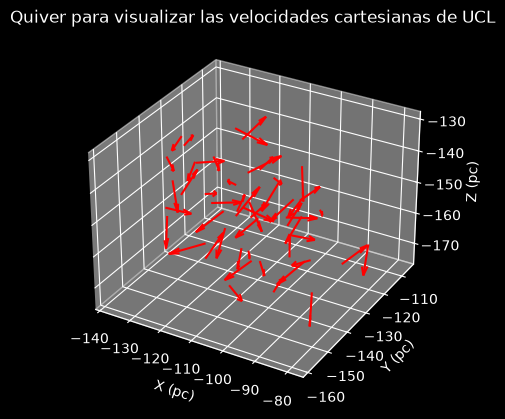

In [176]:
subset_UCL = np.random.choice(len(cartesian_UCL), size=50, replace=False)

# Elejimos aleatoriamente las posiciones
x_subset_UCL = cartesian_UCL[:,0][subset_UCL]
y_subset_UCL = cartesian_UCL[:,1][subset_UCL]
z_subset_UCL = cartesian_UCL[:,2][subset_UCL]

# Así mismo con las velocidades:
vx_subset_UCL = cartesian_UCL[:,3][subset_UCL]
vy_subset_UCL = cartesian_UCL[:,4][subset_UCL]
vz_subset_UCL = cartesian_UCL[:,5][subset_UCL]

ax = plt.figure().add_subplot(projection='3d')

# Hacemos la maya con las posiciones:

ax.quiver(x_subset_UCL, y_subset_UCL, z_subset_UCL,
          vx_subset_UCL, vy_subset_UCL, vz_subset_UCL,
          length=10.0, normalize=True, color='red')

ax.set_title("Quiver para visualizar las velocidades cartesianas de UCL")
ax.set_xlabel('X (pc)')
ax.set_ylabel('Y (pc)')
ax.set_zlabel('Z (pc)')

plt.show()

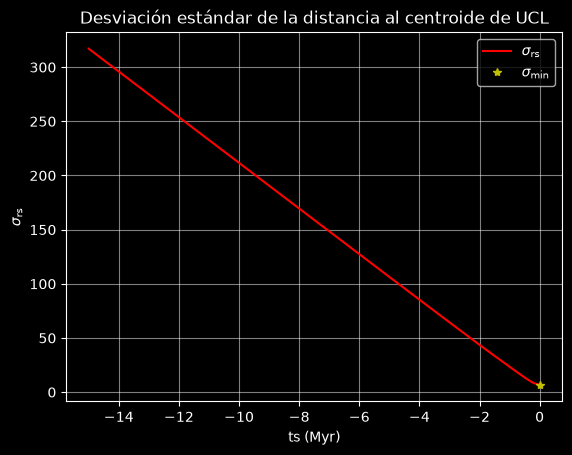

El mínimo de la desviación estándar ocurre en: 0.00 Myr


In [177]:
t_min_UCL = ts[np.argmin(stds_UCL)]
stds_UCL_min = stds_UCL[np.argmin(stds_UCL)]

plt.plot(ts, stds_UCL, 'r-', label=r'$\sigma_\text{rs}$')
plt.plot(t_min_UCL, stds_UCL_min, 'y*', label=r'$\sigma_\text{min}$')
plt.title("Desviación estándar de la distancia al centroide de UCL")
plt.legend(loc='best')
plt.xlabel('ts (Myr)')
plt.ylabel(r'$\sigma_\text{rs}$')
plt.grid(alpha=0.5)
plt.show()

print(f"El mínimo de la desviación estándar ocurre en: {t_min_UCL:.2f} Myr")

# **Declaración de Autoría**

Declaro que el trabajo presentado fue elaborado por mí y en las ocasiones que he utilizado material externo de otros colaboradores o de herramientas de inteligencia articificial han sido debidamente mencionadas y referenciadas en las celdad de código o markdown del notebook.

Si he utilizado herramientas de inteligencia artificial fue exclusivamente en el desarrollo de contenido estético del notebook mas no en el desarrollo matemático que este trae de fondo. Así debo mencionar que algunos gráficos contienen este tipo de ayuda (especialmente los pairplot que fue una recomendación visual para ayuda de manejar mejor los datos).

# **Referencias**

Curso de Minería de Datos:

- Silva Villa, E., & Chaparro Molano, G. (2023). Minería de datos para el pregrado de Astronomía UdeA. https://esilvavilla.github.io/MineriaDatosweb/intro.html

Simbad:

- Wenger, M., Ochsenbein, F., Egret, D., Dubois, P., Bonnarel, F., Borde, S., Genova, F., Jasniewicz, G., Laloë, S., Lesteven, S., & Monier, R. (2000). The SIMBAD astronomical database: The CDS reference database for astronomical objects. Astronomy and Astrophysics Supplement Series, 143(1), 9–22. https://doi.org/10.1051/aas:2000332

Astroquery Gaia DR3:

- Gaia Collaboration, Vallenari, A., Brown, A. G. A., Prusti, T., de Bruijne, J. H. J., Arenou, F., Babusiaux, C., Biermann, M., Creevey, O. L., Ducourant, C., Evans, D. W., Eyer, L., Guerra, R., Hutton, A., Jordi, C., Klioner, S. A., Lammers, U. L., Lindegren, L., Luri, X., ... Zwitter, T. (2023). Gaia Data Release 3: Summary of the content and survey properties. Astronomy & Astrophysics, 674, Artículo A1. doi.org

Astropy

- Astropy Collaboration, Price-Whelan, A. M., Lim, P. L., Earl, N., Starkman, N., Bradley, L., Shupe, D. L., Patil, A. A., Corrales, L., Brasseur, C. E., Nöthe, M., Donath, A., Tollerud, E., Morris, B. M., Ginsburg, A., Vaher, E., Weaver, B. A., Tocknell, J., Jamieson, W., ... Zonca, A. (2022). The Astropy Project: Sustaining and growing a community-oriented open-source project and the latest major release (v5.0) of the core package. The Astrophysical Journal, 935(2), 167. https://doi.org/10.3847/1538-4357/ac7c74